# CVRIE V1 — Partie 1 : Apprentissage supervisé

Classification de cellules sanguines à partir du dataset **BloodMNIST** (MedMNIST v2).


---

## Sommaire
1. Chargement des données
2. Description du dataset
3. Analyse exploratoire
4. Pré-traitement
5. Fonction de perte
6. Entraînement et comparaison de modèles
7. Essais infructueux
8. Conclusions et insights


## 1. Chargement des données




In [1]:
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA = "../data/bloodmnist"

X_train = np.load(f"{DATA}/train_images.npy")
y_train = np.load(f"{DATA}/train_labels.npy")
X_val   = np.load(f"{DATA}/val_images.npy")
y_val   = np.load(f"{DATA}/val_labels.npy")
X_test  = np.load(f"{DATA}/test_images.npy")
y_test  = np.load(f"{DATA}/test_labels.npy")

y_train = y_train.ravel()
y_val   = y_val.ravel()
y_test  = y_test.ravel()

print("train :", X_train.shape, "|", y_train.shape)
print("val   :", X_val.shape,   "|", y_val.shape)
print("test  :", X_test.shape,  "|", y_test.shape)
print("type  :", X_train.dtype, "| pixels de", X_train.min(), "à", X_train.max())


train : (11959, 28, 28, 3) | (11959,)
val   : (1712, 28, 28, 3) | (1712,)
test  : (3421, 28, 28, 3) | (3421,)
type  : uint8 | pixels de 0 à 255


## 2. Description du dataset

BloodMNIST regroupe 17 092 images de cellules sanguines individuelles acquises au
microscope (automate CellaVision DM96) au laboratoire d'hématologie de l'hôpital
Clínic de Barcelone.

**Point déterminant** : toutes les cellules sont **normales**. Les prélèvements
proviennent de patients sans infection, sans maladie hématologique ou oncologique et
sans traitement pharmacologique au moment du prélèvement. Notre modèle identifie donc
un *type* cellulaire, il ne détecte aucune pathologie.

Les images sources (3×360×363) ont été recadrées au centre en 3×200×200 puis réduites
en 3×28×28, soit une perte d'environ 98 % des pixels d'origine.

**Correspondance des labels** (source : documentation officielle MedMNIST) :

| Label | Type cellulaire |
|-------|-----------------|
| 0 | basophile |
| 1 | éosinophile |
| 2 | érythroblaste |
| 3 | granulocytes immatures (myélocytes, métamyélocytes, promyélocytes) |
| 4 | lymphocyte |
| 5 | monocyte |
| 6 | neutrophile |
| 7 | plaquette |

La classe 3 regroupe trois stades de maturation sous une même étiquette : c'est
probablement la classe la plus difficile à isoler.

**Licence** : CC BY 4.0 (le code MedMNIST est sous Apache 2.0).
**Référence** : Yang et al., *MedMNIST v2*, Scientific Data, 2023.
https://doi.org/10.1038/s41597-022-01721-8

Les auteurs précisent que ce dataset n'est pas destiné à un usage clinique.


In [2]:
CLASSES = {
    0: "basophile",
    1: "éosinophile",
    2: "érythroblaste",
    3: "granulocytes immatures",
    4: "lymphocyte",
    5: "monocyte",
    6: "neutrophile",
    7: "plaquette",
}

NOMS = [CLASSES[i] for i in range(8)]


## 3. Analyse exploratoire

### 3.1 Distribution des classes

Le sujet insiste sur le risque des jeux déséquilibrés : si une classe domine largement,
un modèle peut l'exploiter pour afficher une bonne accuracy sans rien apprendre.


In [3]:
classes, counts = np.unique(y_train, return_counts=True)

for c, n in zip(classes, counts):
    print(f"{CLASSES[c]:<24} {n:5d} images  ({n/len(y_train)*100:4.1f} %)")

ratio = counts.max() / counts.min()
print(f"\nRapport majoritaire / minoritaire : {ratio:.1f}")


basophile                  852 images  ( 7.1 %)
éosinophile               2181 images  (18.2 %)
érythroblaste             1085 images  ( 9.1 %)
granulocytes immatures    2026 images  (16.9 %)
lymphocyte                 849 images  ( 7.1 %)
monocyte                   993 images  ( 8.3 %)
neutrophile               2330 images  (19.5 %)
plaquette                 1643 images  (13.7 %)

Rapport majoritaire / minoritaire : 2.7


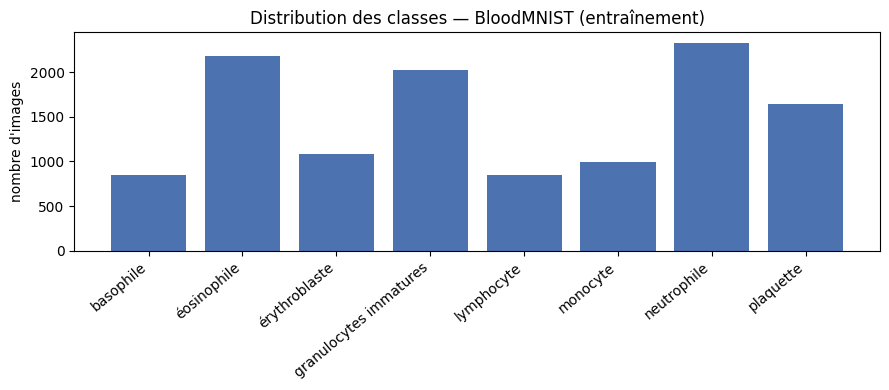

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(NOMS, counts, color="#4C72B0")
ax.set_ylabel("nombre d'images")
ax.set_title("Distribution des classes — BloodMNIST (entraînement)")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()


**Observation** : le déséquilibre est modéré (rapport ≈ 2,7 entre la classe la plus
et la moins représentée). Il est suffisamment marqué pour rendre l'accuracy globale
trompeuse, mais reste assez faible pour ne pas empêcher l'apprentissage des classes
minoritaires.




### 3.2 Aperçu visuel

Un exemple de chaque classe, puis plusieurs exemples par classe pour juger de la
variabilité intra-classe.


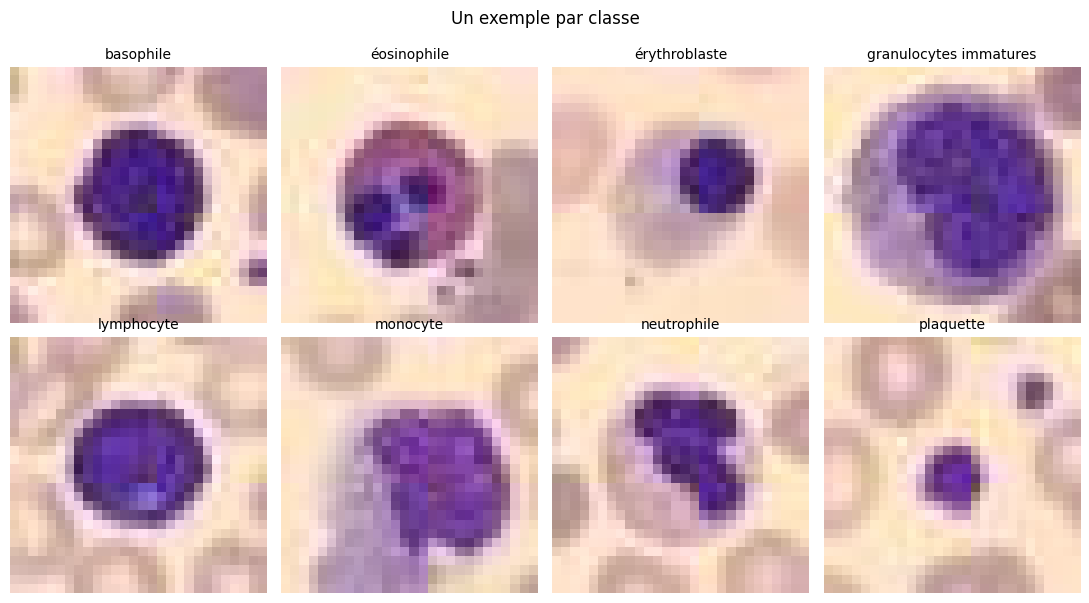

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for c, ax in zip(classes, axes.ravel()):
    idx = np.where(y_train == c)[0][0]
    ax.imshow(X_train[idx], interpolation="nearest")
    ax.set_title(CLASSES[c], fontsize=10)
    ax.axis("off")
plt.suptitle("Un exemple par classe", y=1.0)
plt.tight_layout()
plt.show()


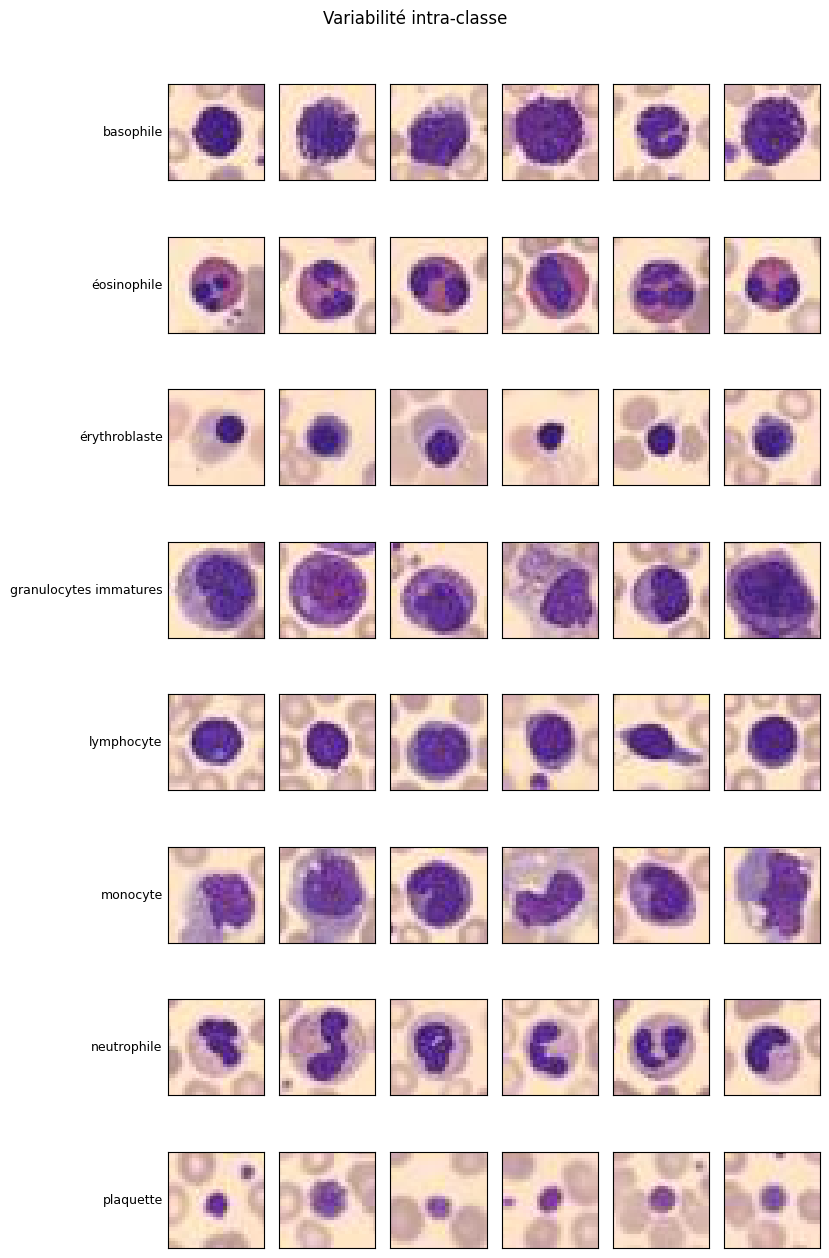

In [6]:
N = 6
fig, axes = plt.subplots(8, N, figsize=(N * 1.4, 8 * 1.6))
for c in classes:
    idx = np.where(y_train == c)[0][:N]
    for j, i in enumerate(idx):
        axes[c, j].imshow(X_train[i], interpolation="nearest")
        axes[c, j].set_xticks([]); axes[c, j].set_yticks([])
    axes[c, 0].set_ylabel(CLASSES[c], rotation=0, ha="right",
                          va="center", fontsize=9)
plt.suptitle("Variabilité intra-classe", y=1.0)
plt.tight_layout()
plt.show()


### 3.3 Couleur ou niveaux de gris ?

Les huit classes partagent une colorimétrie quasi identique (noyau violet, cytoplasme
clair, fond crème) : toutes les images proviennent du même automate avec un protocole
de coloration standardisé. Ce sont les critères **morphologiques** qui distinguent les
types cellulaires — forme du noyau, taille, rapport noyau/cytoplasme.

**Hypothèse** : les trois canaux couleur apportent peu d'information discriminante.
Une conversion en niveaux de gris ferait passer de 2 352 à 784 features, soit une
division par trois du coût de calcul.

Cette hypothèse sera vérifiée expérimentalement dans la section pré-traitement.


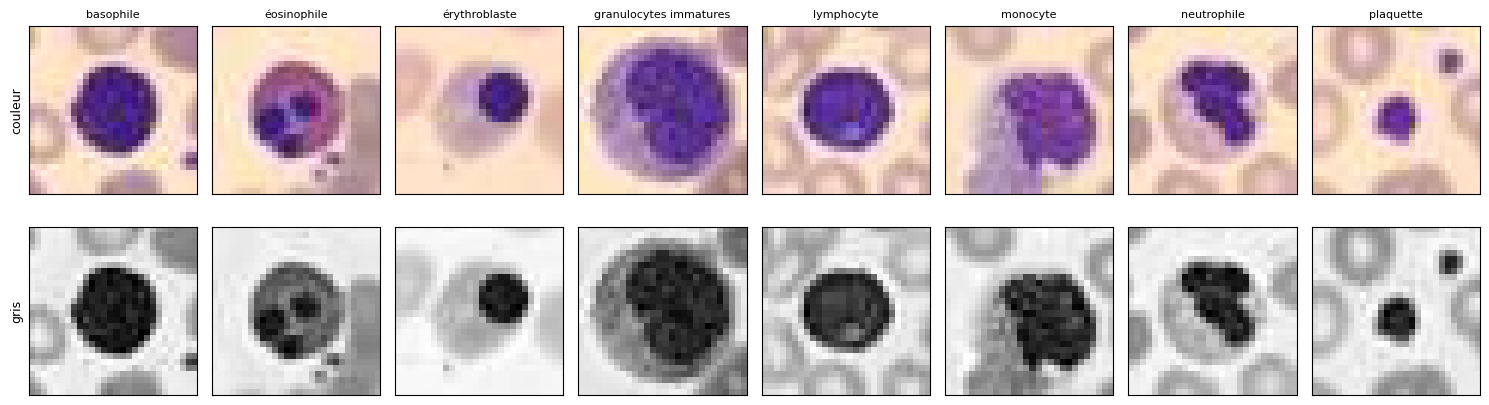

In [7]:
X_train_gray = X_train.mean(axis=3)

fig, axes = plt.subplots(2, 8, figsize=(15, 4.5))
for c in classes:
    i = np.where(y_train == c)[0][0]
    axes[0, c].imshow(X_train[i], interpolation="nearest")
    axes[0, c].set_title(CLASSES[c], fontsize=8)
    axes[1, c].imshow(X_train_gray[i], cmap="gray", interpolation="nearest")
    for r in (0, 1):
        axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
axes[0, 0].set_ylabel("couleur", fontsize=9)
axes[1, 0].set_ylabel("gris", fontsize=9)
plt.tight_layout()
plt.show()


**À compléter après observation** : les classes qui se distinguaient en couleur
restent-elles distinguables en niveaux de gris ?


### 3.4 Limite structurelle de résolution

La réduction de 200×200 à 28×28 fait disparaître les détails fins de texture et de
contour, notamment la lobulation du noyau qui distingue plusieurs types de granulocytes.

Cette limite **plafonne la performance atteignable quel que soit le modèle**. Nous en
tiendrons compte dans l'interprétation des résultats, en distinguant les erreurs
imputables au modèle de celles imputables aux données.


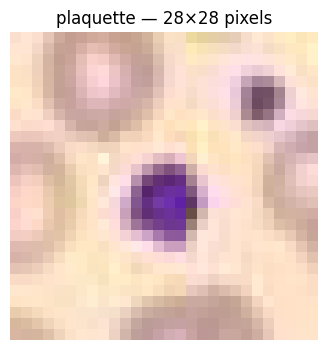

In [8]:
plt.figure(figsize=(4, 4))
plt.imshow(X_train[0], interpolation="nearest")
plt.title(f"{CLASSES[y_train[0]]} — 28×28 pixels")
plt.axis("off")
plt.show()


## 4. Pré-traitement

À faire :
- normalisation des pixels (division par 255)
- aplatissement en vecteurs
- test couleur vs niveaux de gris
- réduction de dimension (PCA) — à justifier
- traitement du déséquilibre de classes


In [9]:
# Normalisation et aplatissement
# X_train_flat = (X_train / 255.0).reshape(len(X_train), -1)


### Split entraînement / évaluation

Le dataset fournit déjà trois partitions officielles (ratio 7:1:2) : 11 959 images
d'entraînement, 1 712 de validation et 3 421 de test.

Nous conservons ce découpage plutôt que de refaire un `train_test_split` : il est
standard, il permet la comparaison avec les résultats publiés, et le jeu de test
reste intouché jusqu'à l'évaluation finale.


## 5. Fonction de perte

| Modèle | Fonction de perte | Intuition |
|---|---|---|
| Régression logistique | log loss (entropie croisée) | pénalise fortement une prédiction confiante et fausse |
| SVM | hinge loss | pénalise les points du mauvais côté de la marge |
| Random Forest | gini / entropie | mesure l'impureté d'un nœud lors des découpes |

Nous retenons la log loss (entropie croisée), fonction de perte de la régression logistique.

Elle convient au problème pour trois raisons. Elle gère nativement le multi-classes, là où la hinge loss du SVM nécessite une décomposition en sous-problèmes binaires. Elle produit des probabilités calibrées plutôt qu'une décision sèche, ce qui permet au système de signaler son incertitude — propriété essentielle en aide au diagnostic, où une prédiction hésitante doit déclencher une vérification humaine. Enfin elle pénalise fortement les erreurs commises avec un haut degré de confiance.

Compte tenu du déséquilibre identifié en section 3 (rapport 2,7), nous utilisons la variante pondérée via class_weight='balanced' : la contribution de chaque échantillon à la perte est inversement proportionnelle à la fréquence de sa classe, ce qui empêche le modèle de négliger les basophiles et les lymphocytes.

## 6. Entraînement et comparaison de modèles




## 7. Essais infructueux

| Essai | Résultat | Pourquoi ça a échoué |
|---|---|---|
|  |  |  |


## 8. Conclusions et insights

- Modèle retenu et performance finale :
- Confusions observées et cohérence biologique :
- Effet du plafond de résolution :
- Usage responsable : ce que ce modèle ne fait pas :
- Pistes d'amélioration :
